<a href="https://colab.research.google.com/github/Rouliiane/2026_Intro_Python/blob/main/part-I/1.6-geospatial-vector-data-environmental-exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Notebook-friendly copy of `part-I/1.6-geospatial-vector-data-environmental-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [2]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# Environmental Exercises

**ℹ️ How to use these exercises**

Attempt each from scratch in the empty code cell. Import geopandas as `gpd`, keep track of the crs at every step, and measure only after reprojecting to a metric crs.

## Exercise 1: Hurricane track analysis

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/nasa-hurricane-florence-2018-09-11.jpg" alt="A satellite view of Hurricane Florence over the Atlantic, a clear eye at the centre of a broad spiral of cloud" width="500">

<em>Hurricane Florence on 11 September 2018, three days before landfall in North Carolina. Image from <a href="https://worldview.earthdata.nasa.gov/">NASA Worldview</a> via <a href="https://commons.wikimedia.org/wiki/File:Florence_2018-09-11_1750Z.jpg">Wikimedia Commons</a>, public domain.</em>


*Can you quickly find out which US states Hurricane Florence passed through using geopandas?*

Apply geopandas to read in the geospatial data, plot, and analyse the track of Hurricane Florence
from 30 August to 18 September 2018. The track is the archived advisory record from the
[National Hurricane Center](https://www.nhc.noaa.gov/); the state boundaries are a
[US Census Bureau](https://www.census.gov/geographies/mapping-files/time-series/geo/carto-boundary-file.html)
cartographic boundary file.

References:

1. [Introduction to GeoPandas](https://geopandas.org/en/stable/getting_started/introduction.html) — geopandas' official website
2. [Geopandas: an introduction](https://autogis-site.readthedocs.io/en/latest/lessons/lesson-2/geopandas-an-introduction.html) — Automating GIS Processes
3. [Use Data for Earth and Environmental Science in Open Source Python](https://www.earthdatascience.org/courses/use-data-open-source-python/)
4. [The Shapely User Manual](https://shapely.readthedocs.io/en/stable/manual.html)
5. [Geospatial Analysis with Python and R](https://kodu.ut.ee/~kmoch/geopython2020/index.html)

In [3]:
# Pre-supplied: download and cache the two real data files.
import pooch

states_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/gz_2010_us_040_00_5m.json",
    known_hash="sha256:7a8c022e063a34a83f35984cde6c81992ece5983f8cc4459ed02e40687739573",
    fname="us_states.geojson",
    path=pooch.os_cache("mlees"),
)
track_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/florence.csv",
    known_hash="sha256:385691583ee41682a1c905e042c56ea362609fb04645934bdda7911c55c8b63f",
    fname="florence.csv",
    path=pooch.os_cache("mlees"),
)

**ℹ️ Where the tools come from**

Every tool the questions need has been demonstrated already. `read_file`, `.plot()`, `GeoDataFrame`,
`gpd.points_from_xy`, `.crs`, `geom_type`, the MultiPolygon type, `.isin()`, `overlay`, `.centroid`,
`to_crs`, `buffer` and the spatial predicates are from this subchapter's lecture; `.head()` and
boolean filtering are from 1.5, and `unique` from 1.5's earthquake exercise. `ax.annotate`, which Q8
uses to label each state, is from 1.4.

**Q1) Import geopandas and pandas.**

Import geopandas as `gpd`, pandas as `pd`, and matplotlib's pyplot as `plt`.

In [4]:
# Import geopandas (as gpd), pandas, and matplotlib
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt


**Q2) Read the state boundary file with geopandas' `read_file` function.**

The file is cached at `states_path`. Call the result `country`.

In [5]:
# Read the data with the geopandas function
country = gpd.read_file(states_path)

**Q3) Have a look at the data. What type of geometries does it contain?**

Print the first few rows, and answer the geometry question in a comment.

In [6]:
# Print out the first few lines of the data

country.head(3)


#it contains the index, the state's number, the state's name, its area and its geometry





,GEO_ID,STATE,NAME,LSAD,CENSUSAREA,geometry
0,0400000US01,01,Alabama,,50645.326,"MULTIPOLYGON (((-88.12466 30.28364, -88.08681 ..."
1,0400000US02,02,Alaska,,570640.950,"MULTIPOLYGON (((-166.10574 53.98861, -166.0752..."
2,0400000US04,04,Arizona,,113594.084,"POLYGON ((-112.53859 37.00067, -112.53454 37.0..."


**Q4) Have a look at the data on a map using geopandas' `.plot()` method.**

Exclude Alaska and Hawaii using the `NAME` attribute and pandas' `.isin()` method. Specify the
figsize to be 30 x 20.

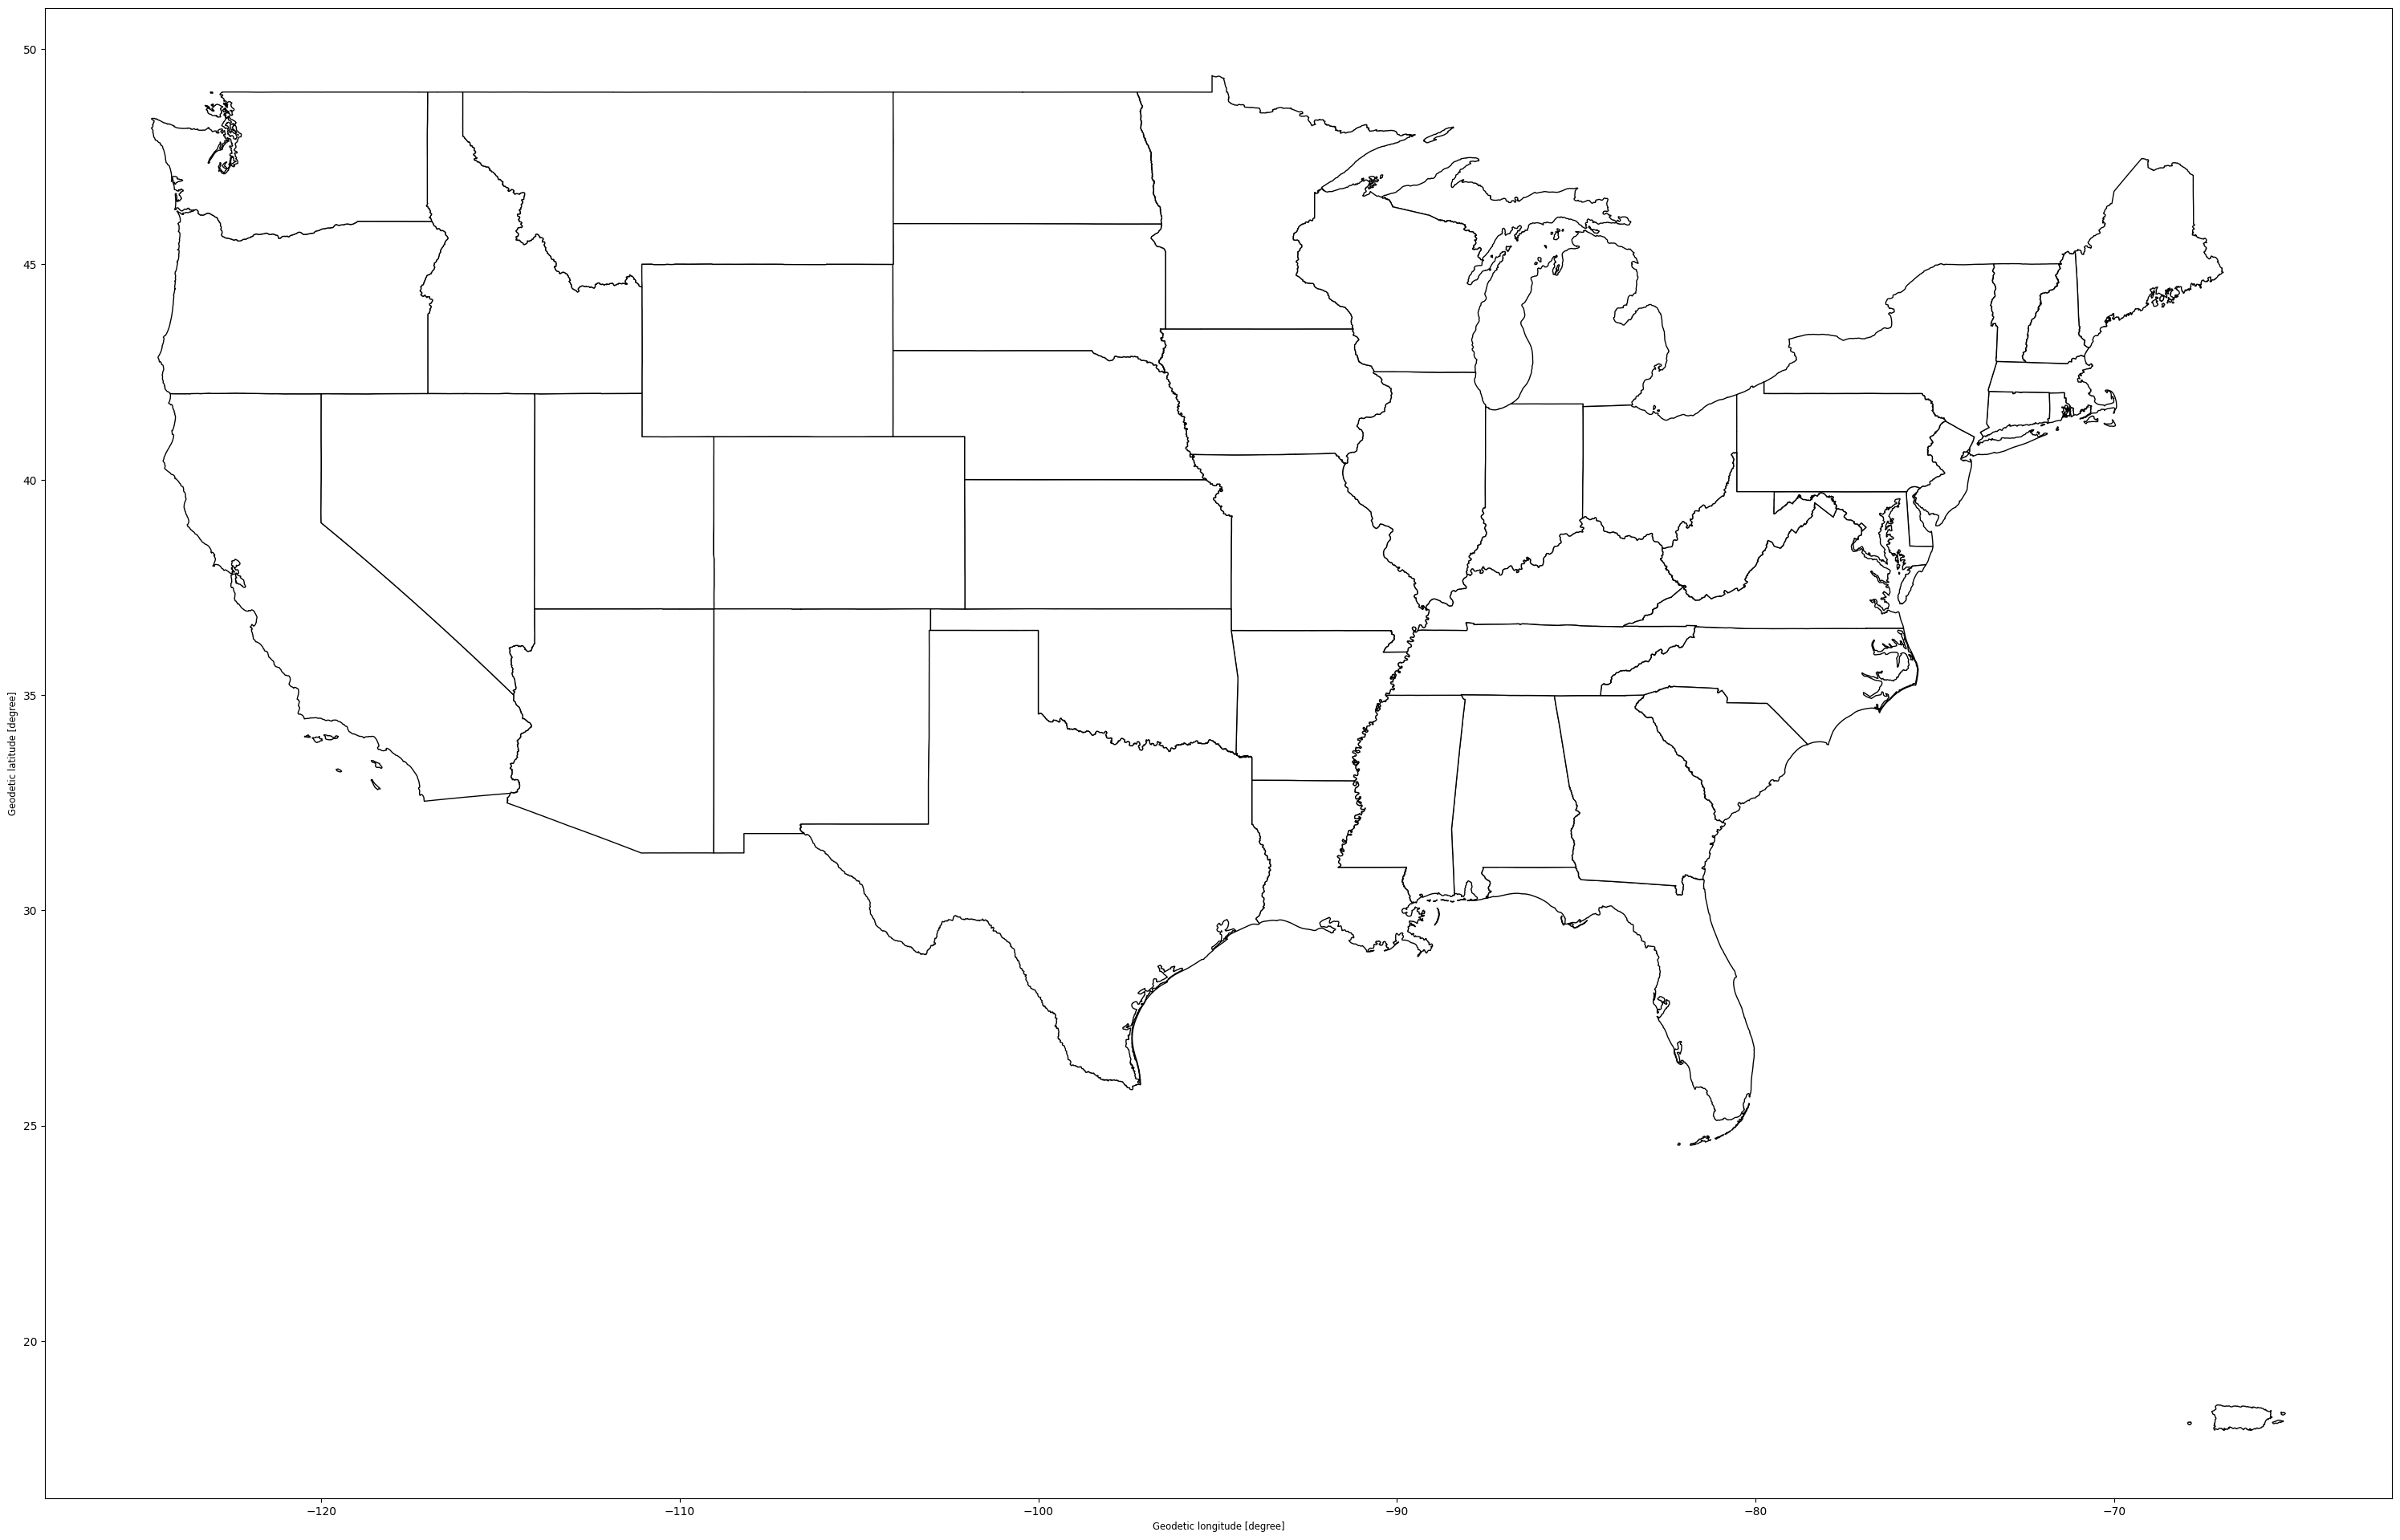

In [7]:
# Plot the US states (Alaska and Hawaii excluded)

states_filtered = country[~country["NAME"].isin(["Alaska", "Hawaii"])]

fig, ax = plt.subplots(figsize=(30, 20))
states_filtered.plot(ax=ax, color='white', edgecolor='black')

fig.tight_layout()
plt.show()

In [16]:
# Pre-supplied: read in the hurricane Florence data, drop the advisory bookkeeping columns,
# fix the longitude sign, and have a look at the dataframe.
# The Long column holds a positive "degrees west" magnitude, not a signed longitude -- a common
# quirk of NHC advisory data.

track_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/florence.csv",
    known_hash="sha256:385691583ee41682a1c905e042c56ea362609fb04645934bdda7911c55c8b63f",
    fname="florence.csv",
    path=pooch.os_cache("mlees"),
)

track = pd.read_csv(track_path)

track.columns

track.head(3)
track.drop(columns=["AdvisoryNumber"])

track["Long"] = -track["Long"]
track.head(3)












,AdvisoryNumber,Date,Lat,Long,Wind,Pres,Movement,Type,Name,Received,Forecaster
0,1,08/30/2018 11:00,12.9,-18.4,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six,08/30/2018 10:45,Avila
1,1A,08/30/2018 14:00,12.9,-19.0,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six,08/30/2018 13:36,Avila
2,2,08/30/2018 17:00,12.9,-19.4,30,1007,W at 9 MPH (280 deg),Potential Tropical Cyclone,Six,08/30/2018 16:36,Avila


**Q5) Create a GeoDataFrame from the `florence` DataFrame.**

Build the geometry column from the `Long` and `Lat` columns with
[`gpd.points_from_xy`](https://geopandas.org/en/stable/docs/reference/api/geopandas.points_from_xy.html),
and call the result `gdf_florence`. Then look at its first few rows.

In [20]:
# Create a geodataframe from the hurricane florence dataframe

import geopandas as gpd

gdf_track = gpd.GeoDataFrame(
    track,
    geometry=gpd.points_from_xy(track["Long"], track["Lat"])
)

gdf_track.head()







,AdvisoryNumber,Date,Lat,Long,Wind,Pres,Movement,Type,Name,Received,Forecaster,geometry
0,1,08/30/2018 11:00,12.9,-18.4,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six,08/30/2018 10:45,Avila,POINT (-18.4 12.9)
1,1A,08/30/2018 14:00,12.9,-19.0,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six,08/30/2018 13:36,Avila,POINT (-19 12.9)
2,2,08/30/2018 17:00,12.9,-19.4,30,1007,W at 9 MPH (280 deg),Potential Tropical Cyclone,Six,08/30/2018 16:36,Avila,POINT (-19.4 12.9)
3,2A,08/30/2018 20:00,13.1,-20.4,30,1007,W at 11 MPH (280 deg),Potential Tropical Cyclone,Six,08/30/2018 19:44,Beven,POINT (-20.4 13.1)
4,3,08/30/2018 23:00,13.2,-20.9,35,1007,W at 13 MPH (280 deg),Potential Tropical Cyclone,Six,08/30/2018 22:42,Beven,POINT (-20.9 13.2)


**Q6) Plot the US states map (without Alaska and Hawaii) and hurricane Florence together.**

Draw the states as a base map, then plot the hurricane positions on top in a colour that stands
out.

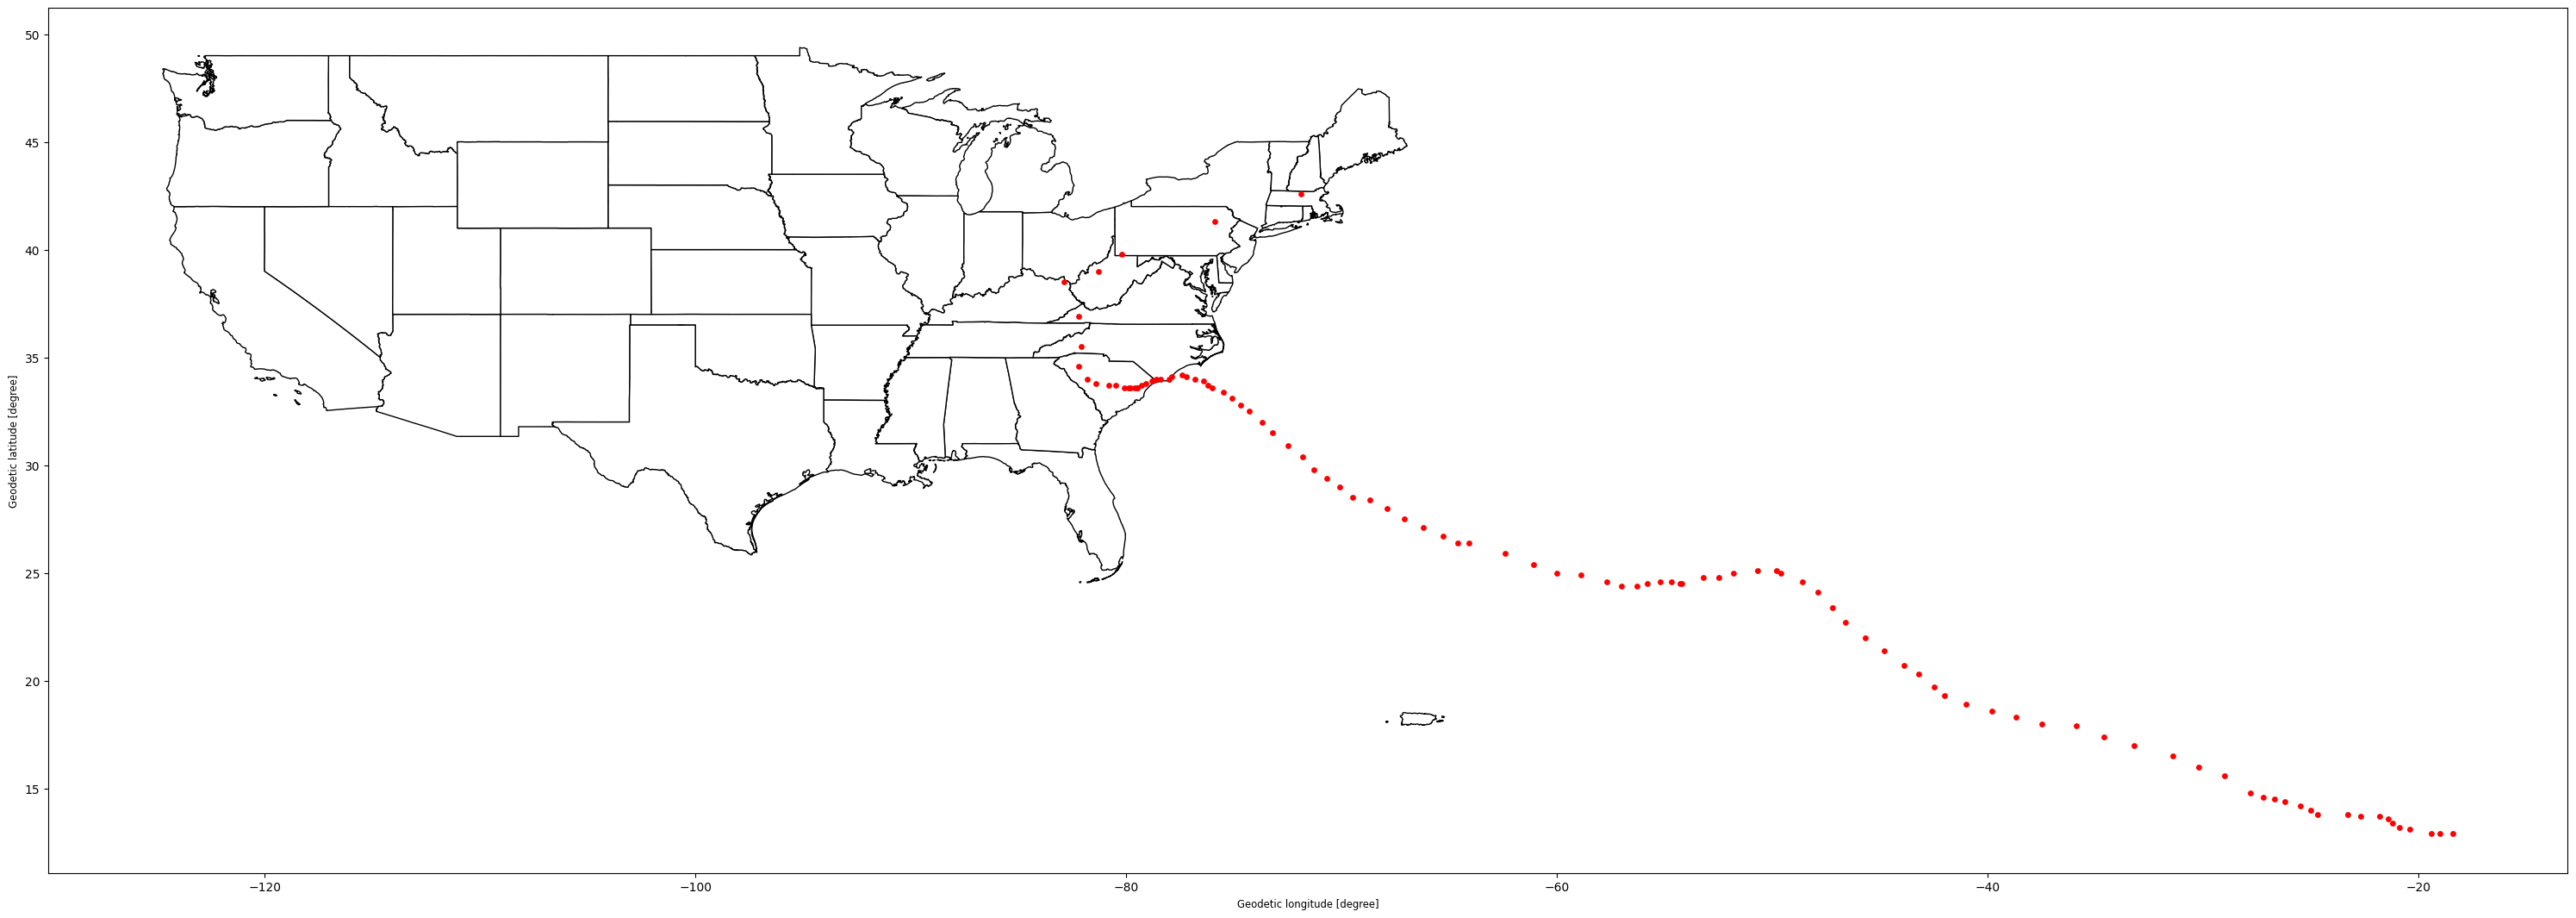

In [30]:
# Plot to see the hurricane overlay the US map, with the hurricane position on top

states_filtered = country[~country["NAME"].isin(["Alaska", "Hawaii"])]

fig, ax = plt.subplots(1, 1, figsize=(30, 20))

# Plot the US states
states_filtered.plot(ax=ax, color='white', edgecolor='black')

# Plot the hurricane track on top in red
gdf_track.plot(ax=ax, color='red', markersize=15, label='Hurricane Florence')

fig.tight_layout()
plt.show()

**Q7) What is the coordinate reference system of the data?**

Check it for both layers, and say in a comment whether they match — two layers only line up on
one pair of axes if they share a crs.

In [36]:
# Check the coordinate reference system of the data

# Assign EPSG:4326 to gdf_track since it was created from raw lon/lat without a specified CRS
if gdf_track.crs is None:
    gdf_track.set_crs("EPSG:4326", inplace=True)

print("crs states:", states_filtered.crs.to_epsg() if states_filtered.crs else None)
print("crs track:", gdf_track.crs.to_epsg() if gdf_track.crs else None)

# Do they match?
# Yes, both are EPSG:4326 (WGS 84).

crs states: 4326
crs track: 4326


**Q8) Which states did the hurricane pass through?**

```{hint}
One approach is to plot the trajectory over the US map, annotate each state with its name, and
read the answer off the figure. Other approaches are more than welcome — `overlay` with
`how="intersection"` will give you the track points that fall inside a state polygon, and the
`NAME` column of the result then answers the question directly.
```

États traversés : ['North Carolina' 'South Carolina' 'Virginia' 'Kentucky' 'West Virginia'
 'Pennsylvania' 'Massachusetts']
Nombre de points conservés : 25


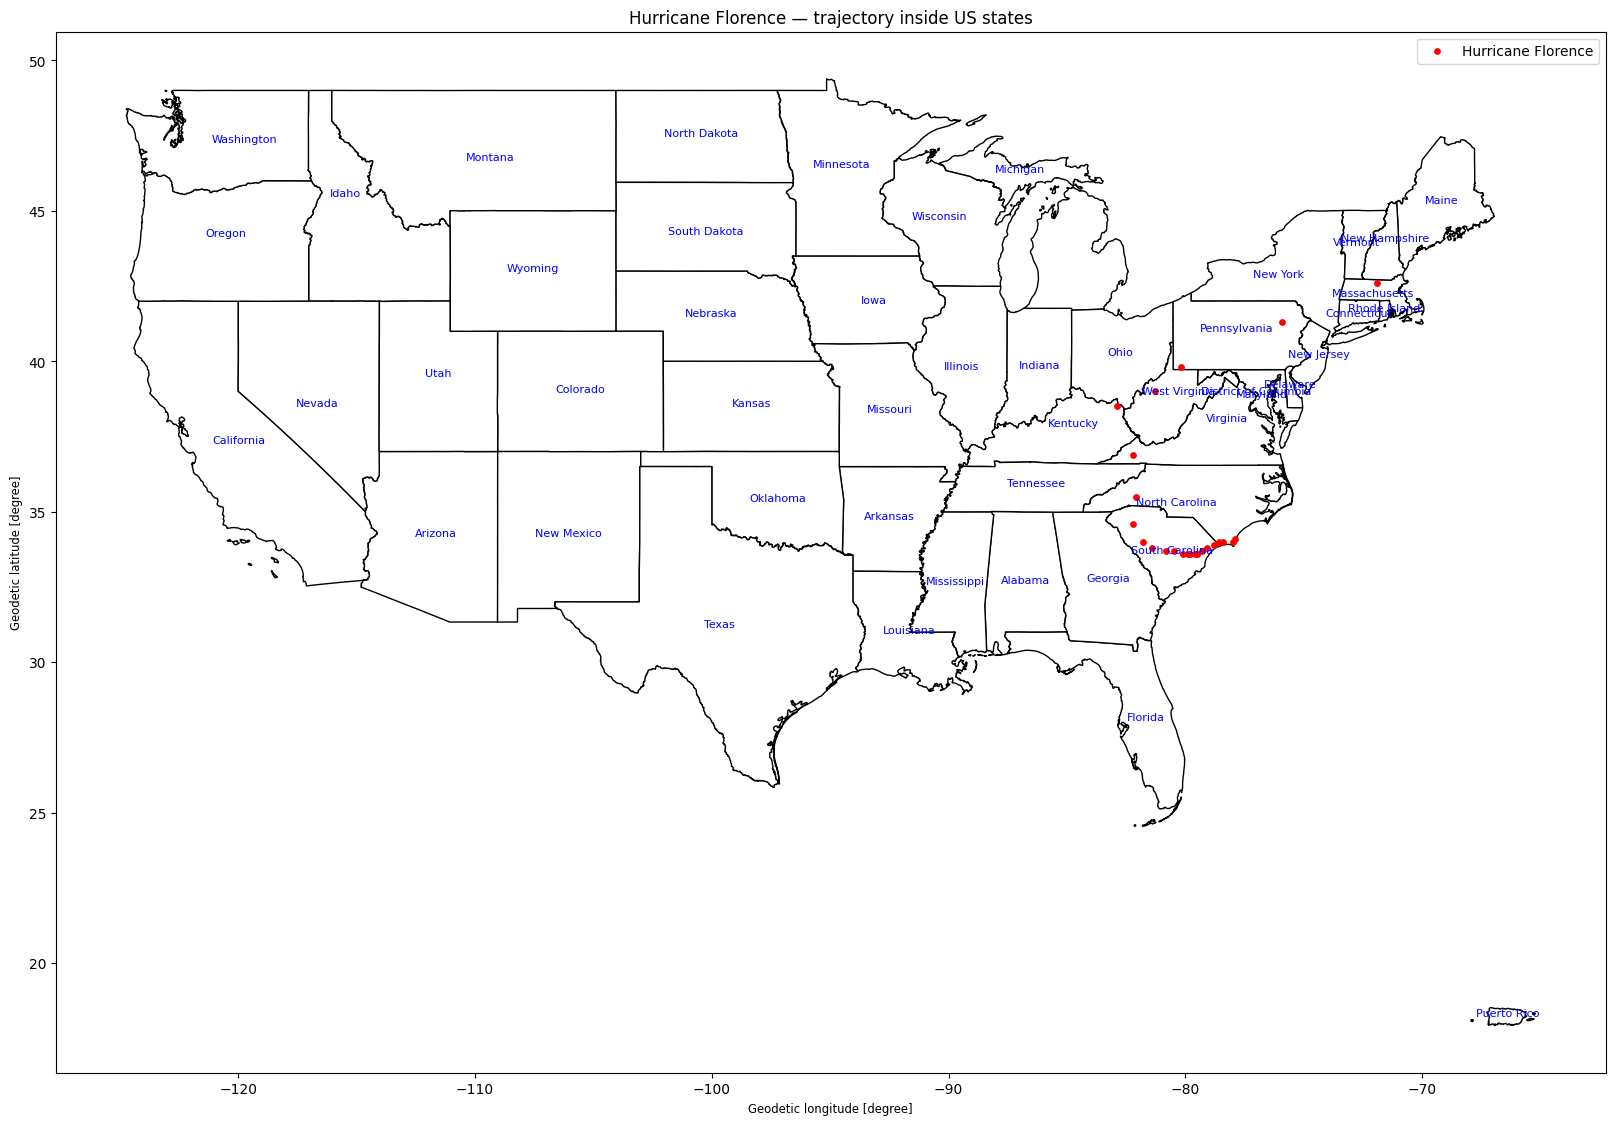

In [49]:

import geopandas as gpd
import matplotlib.pyplot as plt

# 1. Exclude Alaska and Hawaii
states_filtered = country[
    ~country["NAME"].isin(["Alaska", "Hawaii"])
].copy()

# 2. Keep only hurricane points inside US states
track_inside = gpd.overlay(
    gdf_track,
    states_filtered[["NAME", "geometry"]],
    how="intersection"
)

# 3. Create figure
fig, ax = plt.subplots(figsize=(20, 14))

# 4. Plot states
states_filtered.plot(
    ax=ax,
    color="white",
    edgecolor="black"
)

# 5. Annotate states
points = states_filtered.geometry.representative_point()

for nom, point in zip(states_filtered["NAME"], points):
    ax.annotate(
        nom,
        xy=(point.x, point.y),
        fontsize=8,
        color="blue",
        ha="center"
    )

# 6. Plot only the points inside the states
track_inside.plot(
    ax=ax,
    color="red",
    markersize=15,
    label="Hurricane Florence"
)

print("États traversés :", track_inside["NAME"].unique())
print("Nombre de points conservés :", len(track_inside))

ax.legend()
ax.set_title("Hurricane Florence — trajectory inside US states")
plt.show()
